<a href="https://colab.research.google.com/github/sadmansakib18/CVPR-TASK-1-MID/blob/main/CNN_2nd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [74]:
import gdown
import zipfile
import os
import shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchsummary import summary
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cpu


In [75]:
file_id = '1T7AiZdRBtwxRV7_Inim82szlPyNfRHs5'
gdown.download(id=file_id, output='data.zip', quiet=False)

with zipfile.ZipFile('data.zip', 'r') as z:
    z.extractall('data')

# Check the folder names inside 'data'
for root, dirs, files in os.walk('data'):
    print(root, dirs)

Downloading...
From (original): https://drive.google.com/uc?id=1T7AiZdRBtwxRV7_Inim82szlPyNfRHs5
From (redirected): https://drive.google.com/uc?id=1T7AiZdRBtwxRV7_Inim82szlPyNfRHs5&confirm=t&uuid=4ec7b76e-44b0-467f-b29f-07737f036d1d
To: /content/data.zip
100%|██████████| 434M/434M [00:09<00:00, 47.3MB/s]


data ['Multi-Source Agricultural Image Dataset for Robust']
data/Multi-Source Agricultural Image Dataset for Robust ['Multi-Source Agricultural Image Dataset for Robust Classification and Semantic\xa0Segmentation']
data/Multi-Source Agricultural Image Dataset for Robust/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation ['Vegetables', 'Fruits', 'Flowers', 'Crops or Grains']
data/Multi-Source Agricultural Image Dataset for Robust/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation/Vegetables ['Wax Gourd', 'Spiny Gourd', 'Radish', 'Turnip', 'Bottle Gourd', 'Capsicum', 'Pointed Gourd', 'Cabbage', 'Eggplant', 'Carrot', 'Potato', 'Beans', 'Yardlong beans', 'Cauliflower', 'Green chili', 'Beetroot', 'Bitter Gourd', 'Tomato', 'Red Amaranth', 'Pumpkin', 'Sponge Gourd', 'Taro leaves', 'Coriander']
data/Multi-Source Agricultural Image Dataset for Robust/Multi-Source Agricultural Image Dataset for Robust Classificatio

In [76]:
image_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff')

# Extract any nested zip files if present
for root, dirs, files in os.walk("data"):
    for f in files:
        if f.lower().endswith(".zip"):
            with zipfile.ZipFile(os.path.join(root, f), 'r') as z:
                z.extractall(root)

os.makedirs("agri_classes", exist_ok=True)

for root, dirs, files in os.walk("data"):
    # Skip Mac metadata folders if present
    if "__MACOSX" in root:
        continue
    imgs = [f for f in files if f.lower().endswith(image_exts)]
    if len(imgs) > 0:
        class_name = os.path.basename(root)
        dest_dir = os.path.join("agri_classes", class_name)
        os.makedirs(dest_dir, exist_ok=True)
        for img in imgs:
            shutil.copy2(os.path.join(root, img), os.path.join(dest_dir, img))

print("Total Classes:", len(os.listdir("agri_classes")))
print("Sample Classes:", sorted(os.listdir("agri_classes"))[:10])

Total Classes: 77
Sample Classes: ['Apple', 'Banana', 'Beans', 'Beetroot', 'Bitter Gourd', 'Bottle Gourd', 'Brunfelsia', 'Cabbage', 'Capsicum', 'Carrot']


In [77]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [78]:
full_dataset = datasets.ImageFolder("agri_classes")
num_classes = len(full_dataset.classes)

train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

generator = torch.Generator().manual_seed(42)
train_subset, test_subset = random_split(full_dataset, [train_size, test_size], generator=generator)

class ApplyTransform(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __getitem__(self, idx):
        x, y = self.subset[idx]
        return self.transform(x), y
    def __len__(self):
        return len(self.subset)

train_data = ApplyTransform(train_subset, train_transform)
test_data = ApplyTransform(test_subset, val_transform)

print("Number of classes:", num_classes)
print("Train images:", len(train_data))
print("Test images:", len(test_data))

Number of classes: 77
Train images: 4324
Test images: 1081


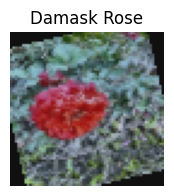

In [79]:
plt.figure(figsize=(2, 2))
plt.imshow(train_data[0][0].permute(1, 2, 0))
plt.title(full_dataset.classes[train_data[0][1]])
plt.axis('off')
plt.show()

In [80]:
batch_size = 32
learning_rate = 0.001
minimum_learning_rate = 1e-4
epochs = 15

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

In [81]:
class CNNModel(nn.Module):
    def __init__(self, num_classes):
        super(CNNModel, self).__init__()

        # Convolutional layers
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU()
        )

        # Fully connected layers / Classification Head
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

In [82]:
model = CNNModel(num_classes=num_classes).to(device)
optimizer = Adam(model.parameters(), lr=learning_rate)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate)
criterion = nn.CrossEntropyLoss()

summary(model, input_size=(3, 64, 64))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
         MaxPool2d-2           [-1, 64, 31, 31]               0
              ReLU-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
         MaxPool2d-5          [-1, 128, 14, 14]               0
              ReLU-6          [-1, 128, 14, 14]               0
            Conv2d-7          [-1, 128, 12, 12]         147,584
         MaxPool2d-8            [-1, 128, 6, 6]               0
              ReLU-9            [-1, 128, 6, 6]               0
          Flatten-10                 [-1, 4608]               0
           Linear-11                  [-1, 256]       1,179,904
             ReLU-12                  [-1, 256]               0
          Dropout-13                  [-1, 256]               0
           Linear-14                   

In [83]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), correct / total

def validate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total

In [84]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
    print("----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

----------------------------------------------------
Epoch 1/15, LR: 0.001
Train Loss: 4.2936 | Train Acc: 0.0178
Val Loss: 4.0868 | Val Acc: 0.0241
----------------------------------------------------
Epoch 2/15, LR: 0.000990166
Train Loss: 3.8716 | Train Acc: 0.0592
Val Loss: 3.3845 | Val Acc: 0.1508
----------------------------------------------------
Epoch 3/15, LR: 0.000961095
Train Loss: 3.2942 | Train Acc: 0.1475
Val Loss: 2.6977 | Val Acc: 0.2803
----------------------------------------------------
Epoch 4/15, LR: 0.000914058
Train Loss: 2.7501 | Train Acc: 0.2505
Val Loss: 2.1437 | Val Acc: 0.4107
----------------------------------------------------
Epoch 5/15, LR: 0.000851109
Train Loss: 2.3245 | Train Acc: 0.3427
Val Loss: 1.8175 | Val Acc: 0.5199
----------------------------------------------------
Epoch 6/15, LR: 0.000775
Train Loss: 2.0041 | Train Acc: 0.4262
Val Loss: 1.5323 | Val Acc: 0.5698
----------------------------------------------------
Epoch 7/15, LR: 0.00068905

In [85]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Number of Classes:", num_classes)
print("Train Images:", len(train_data))
print("Test Images:", len(test_data))
print(f"Best Accuracy (%): {max(val_accuracies) * 100:.2f}")
print(f"Best Loss: {min(val_losses):.4f}")
print("Epochs Trained:", epochs)
print("Used Learning Rate:", learning_rate)
print("Total Trainable Parameters:", trainable_params)

Number of Classes: 77
Train Images: 4324
Test Images: 1081
Best Accuracy (%): 76.69
Best Loss: 0.8048
Epochs Trained: 15
Used Learning Rate: 0.001
Total Trainable Parameters: 1422925


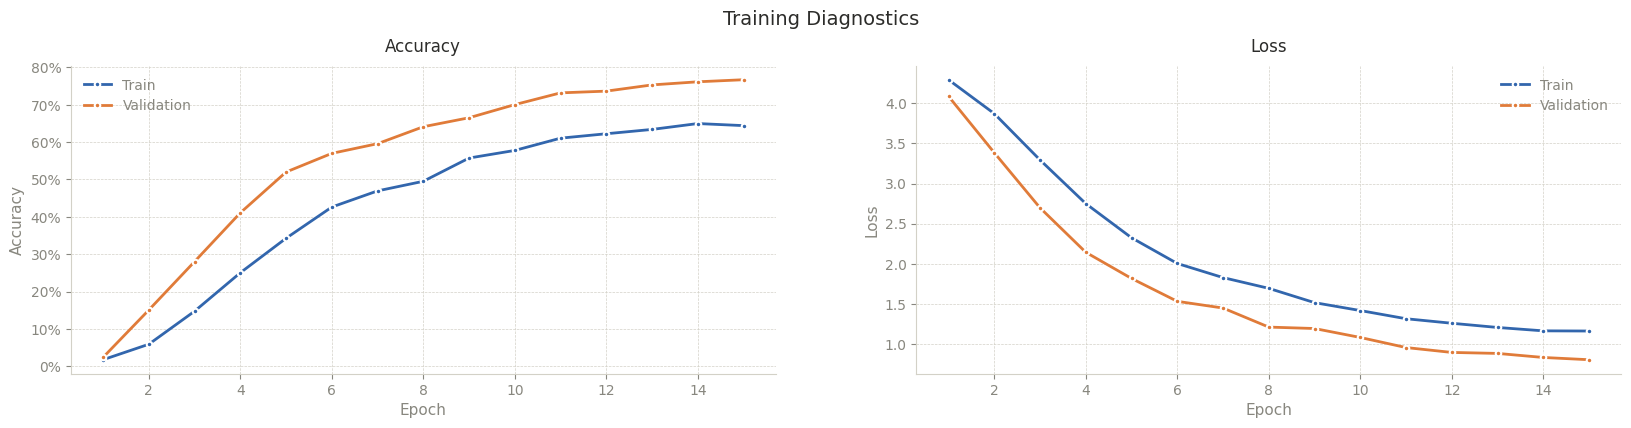

In [86]:
BLUE   = "#3266ad"
ORANGE = "#e07b39"
GRAY   = "#88877f"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d1c7",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#d3d1c7",
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

epochs_number = np.arange(1, epochs + 1)

fig = plt.figure(figsize=(20, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2)

# Accuracy
ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax1.plot(epochs_number, val_accuracies,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax1.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
ax1.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax1.set_ylabel("Accuracy", color=GRAY, fontsize=11)
ax1.set_title("Accuracy", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax1.legend(frameon=False, fontsize=10, labelcolor=GRAY)

# Loss
ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax2.plot(epochs_number, val_losses,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax2.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax2.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax2.set_ylabel("Loss",  color=GRAY, fontsize=11)
ax2.set_title("Loss", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax2.legend(frameon=False, fontsize=10, labelcolor=GRAY)

fig.suptitle("Training Diagnostics", fontsize=14, fontweight="medium", color="#2c2c2a", y=1.02)
plt.savefig("training_curves.pdf", bbox_inches="tight", dpi=150)
plt.show()

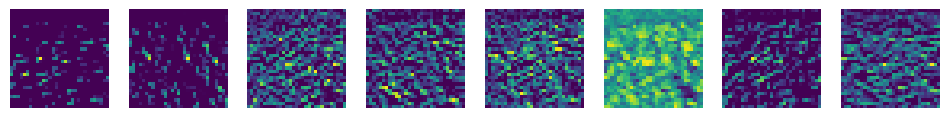

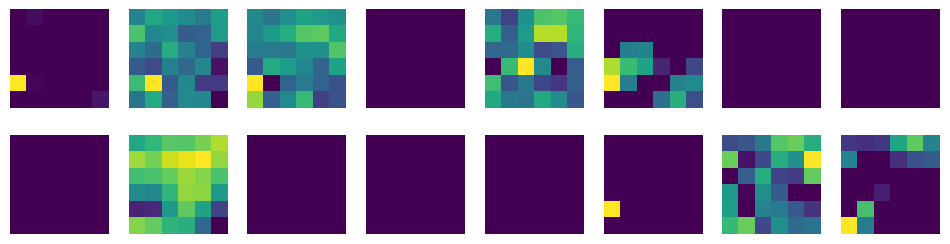

In [87]:
img, label = test_data[0]
x = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    x = model.conv_layers[0](x)
    x = model.conv_layers[1](x)
    early = model.conv_layers[2](x).cpu()[0]

    x = model.conv_layers[3](x)
    x = model.conv_layers[4](x)
    x = model.conv_layers[5](x)
    x = model.conv_layers[6](x)
    x = model.conv_layers[7](x)
    last = model.conv_layers[8](x).cpu()[0]

# Plot first 8 maps from early conv layer
plt.figure(figsize=(12, 2))
for i in range(8):
    plt.subplot(1, 8, i+1)
    plt.imshow(early[i], cmap='viridis')
    plt.axis('off')
plt.show()

# Plot first 16 maps from last conv layer
plt.figure(figsize=(12, 3))
for i in range(16):
    plt.subplot(2, 8, i+1)
    plt.imshow(last[i], cmap='viridis')
    plt.axis('off')
plt.show()